In [1]:
%pip install -U langgraph langchain-groq

  Attempting uninstall: langgraph
    Found existing installation: langgraph 1.2.19
    Uninstalling langgraph-1.2.19:
      Successfully uninstalled langgraph-1.2.19
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [langgraph]


In [5]:
from langgraph.graph import StateGraph ,START,END
from langchain_groq import ChatGroq
from typing import TypedDict,Annotated,Literal
from pydantic import BaseModel, Field
import operator
from google.colab import userdata

In [3]:
# Retrieve Groq API key from Colab Secrets
groq_api_key = userdata.get("GROQ_API_KEY")

# Initialize the model
model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    api_key=groq_api_key
)

In [24]:
class SentimentSchema(BaseModel):
  sentiment: Literal["positive", "negative"]=Field(description='Sentiment of the review')


In [25]:
class DiagnosisSchema(BaseModel):
  issue_type: Literal["UX","PERFORMANCE","BUG","SUPPORT","OTHER"]=Field(description='The category of the issue mentioned')
  tone: Literal["angry","frustrated","disappointed","calm"]=Field(description='The emotional tone expressed by the user')
  urgency: Literal["low","medium","high"]


In [26]:
structured_model=model.with_structured_output(SentimentSchema)
structured_model2=model.with_structured_output(DiagnosisSchema)


In [27]:
prompt='What is the sentiment of the following review - The software is too good'
structured_model.invoke(prompt).sentiment

'positive'

In [28]:
class ReviewState(TypedDict):
  review:str
  sentiment: Literal["positive","negative"]
  diagnosis:dict
  response:str

In [29]:
def find_sentiment(state: ReviewState):
  prompt=f'For the following review find out the sentiment \n {state["review"]}'
  sentiment=structured_model.invoke(prompt).sentiment
  return {"sentiment":sentiment}

In [30]:
def check_sentiment(state: ReviewState)->Literal["positive_response","run_diagnosis"]:
  if state['sentiment']=='positive':
    return 'positive_response'
  else:
    return 'run_diagnosis'


In [31]:
def positive_response(state: ReviewState):

    prompt = f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
Also, kindly ask the user to leave feedback on our website."""

    response = model.invoke(prompt).content

    return {'response': response}

In [32]:
def run_diagnosis(state: ReviewState):
  prompt = f"""Diagnose this negative review:\n\n{state['review']}\n"
    "Return issue_type, tone, and urgency.
"""
  response=structured_model2.invoke(prompt)
  return {'diagnosis':response.model_dump()}


In [33]:
def negative_response(state: ReviewState):

    diagnosis = state['diagnosis']

    prompt = f"""You are a support assistant.
The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
Write an empathetic, helpful resolution message.
"""
    response = model.invoke(prompt).content

    return {'response': response}

In [34]:
graph=StateGraph(ReviewState)
graph.add_node('find_sentiment',find_sentiment)
graph.add_node('positive_response',positive_response)
graph.add_node('run_diagnosis',run_diagnosis)
graph.add_node('negative_response',negative_response)

#start adding edges

graph.add_edge(START,'find_sentiment')
graph.add_conditional_edges('find_sentiment',check_sentiment)
graph.add_edge('positive_response',END)
graph.add_edge('run_diagnosis','negative_response')
graph.add_edge('negative_response',END)

workflow=graph.compile()

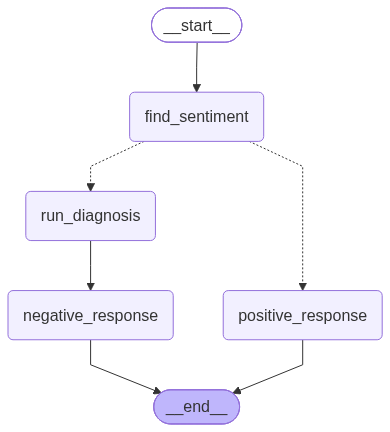

In [35]:
workflow

In [36]:
intial_state={
    'review': "I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality."
}
workflow.invoke(intial_state)

{'review': 'I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality.',
 'sentiment': 'negative',
 'diagnosis': {'issue_type': 'BUG', 'tone': 'angry', 'urgency': 'high'},
 'response': 'Hi\u202f[Name],\n\nI’m really sorry you’ve run into this bug—it’s completely understandable how frustrating that can be, especially when you need things to work right away. Thank you for letting us know, and I’m treating this as a top‑priority issue.\n\n**What’s happening:**  \nFrom what you described, the problem appears to be [briefly summarize the reported symptom, e.g., “the app crashing every time you try to submit a form”]. This is not the experience we want you to have, and I’m committed to getting it fixed as quickly as possible.\n\n**Immediate steps you can try right now**\n\n1. **Clear cache / temporary files** – sometimes s